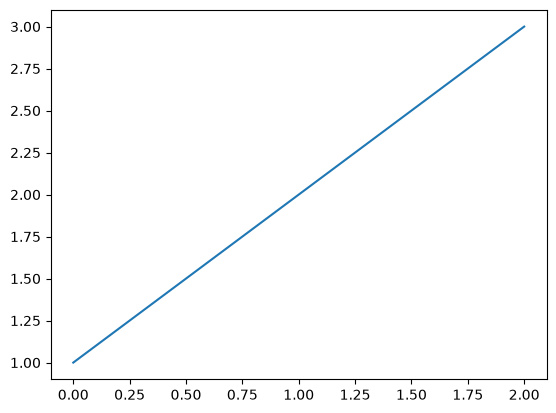

In [1]:
import matplotlib.pyplot as plt
plt.plot([1, 2, 3])
plt.show()

# 04 Clustering: a typology of Russian monotowns

**Goal:** group monotowns into types by their demographic and economic trajectory, then see where Slantsy (item 109 in Order 469-р) fits.

**Data:** `data/processed/features.csv` from notebook 03: 247 monotowns, of which 228 have all five clustering variables (`in_clustering == True`). Towns with missing values are left out rather than imputed.

**Clustering variables**

| variable | meaning | years |
|---|---|---|
| `pop_change_pct` | population change, % | 2017 to 2025 |
| `net_mig_per_1000` | average yearly net migration per 1,000 residents | 2021-2023 |
| `wage_rel` | average wage relative to the regional median of districts and okrugs | 2025 |
| `jobs_per_1000` | employees of large and medium organisations per 1,000 residents | 2025 |
| `job_change_pct` | change in the number of those employees, % | 2017 to 2025 |

The industry share (mining + manufacturing) is not used to build clusters: Rosstat hides the data of dominant employers for confidentiality, so it is only a lower bound. It is used later to describe the clusters.

In [2]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

In [3]:
# oktmo codes stay text (some start with 0)
features = pd.read_csv(
    "../data/processed/features.csv",
    dtype={"oktmo": str, "oktmo_stable": str, "wage_key": str},
)

CLUSTER_VARS = ["pop_change_pct", "net_mig_per_1000", "wage_rel",
                "jobs_per_1000", "job_change_pct"]

df = features[features["in_clustering"]].copy().reset_index(drop=True)

print("All monotowns:", features.shape)
print("In clustering:", df.shape)
print("Missing values in clustering vars:", df[CLUSTER_VARS].isna().sum().sum())

# Slantsy should be in the sample
SLANTSY = 109
df.loc[df["number"] == SLANTSY, ["number", "name_en", "region_en", "category"] + CLUSTER_VARS]

All monotowns: (247, 31)
In clustering: (228, 31)
Missing values in clustering vars: 0


,number,name_en,region_en,category,pop_change_pct,net_mig_per_1000,wage_rel,jobs_per_1000,job_change_pct
90,109,Slantsy,Leningrad Oblast,2,1.13202,3.54558,0.990582,138.700823,-0.55756


In [4]:
df[CLUSTER_VARS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pop_change_pct,228.0,-9.21,7.93,-31.13,-13.11,-9.13,-5.64,37.29
net_mig_per_1000,228.0,-1.44,6.14,-30.03,-4.70,-1.38,1.46,34.72
wage_rel,228.0,1.14,0.25,0.73,0.99,1.09,1.25,2.85
jobs_per_1000,228.0,237.19,93.15,61.38,171.52,219.16,268.49,618.30
job_change_pct,228.0,-5.10,18.78,-42.42,-14.56,-8.12,-0.42,101.83


## Distributions and outliers

K-means groups towns by distance, so it is sensitive to scale and to extreme values. Before scaling, we check how each variable is distributed, which towns are extreme, and whether any two variables measure nearly the same thing (strongly correlated variables would count twice in the distance).

An outlier here is a town more than 3 standard deviations from the mean (|z| > 3).

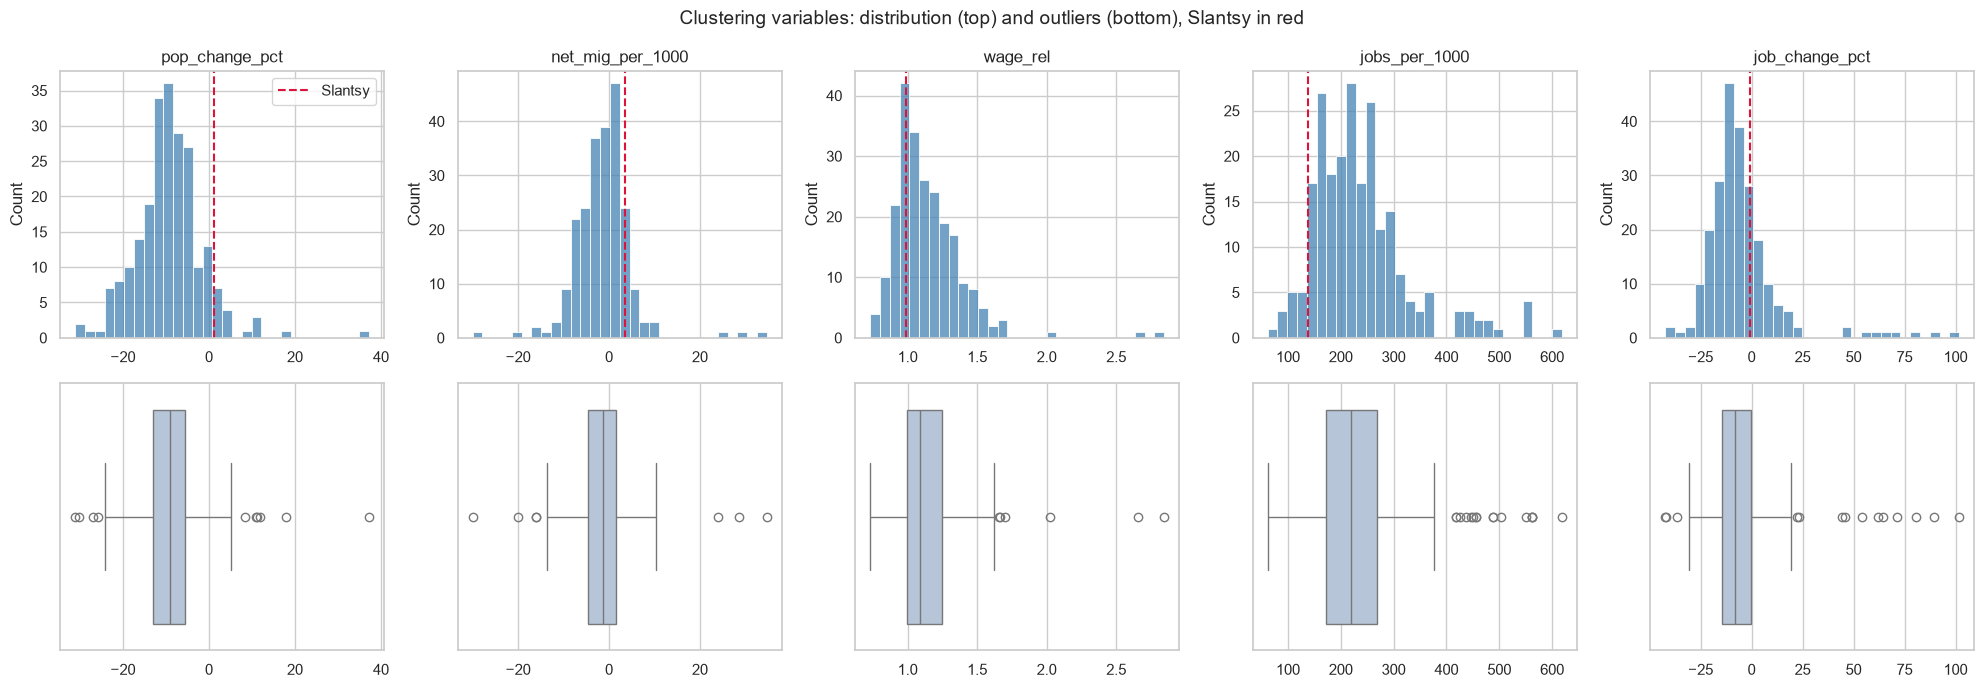

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))

for i, var in enumerate(CLUSTER_VARS):
    sns.histplot(df[var], bins=30, ax=axes[0, i], color="steelblue")
    axes[0, i].axvline(df.loc[df["number"] == SLANTSY, var].iloc[0],
                       color="crimson", linestyle="--", label="Slantsy")
    axes[0, i].set_title(var)
    axes[0, i].set_xlabel("")
    sns.boxplot(x=df[var], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_xlabel("")

axes[0, 0].legend()
plt.suptitle("Clustering variables: distribution (top) and outliers (bottom), Slantsy in red",
             fontsize=14)
plt.tight_layout()
plt.show()